# Import python modules, which allow us to use prebuilt functions for data analysis

In [143]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

# First we load up our google drive
### You don't need to understand how this works fully, just some google drive stuff

In [144]:
# 1. List the contents of your main Google Drive folder (My Drive)
mydrive_path = '/content/drive/MyDrive/'
if os.path.exists(mydrive_path):
    print("Folders and files in your Google Drive:")
    for item in os.listdir(mydrive_path):
        if os.path.isdir(os.path.join(mydrive_path, item)):
            print(f"  [Folder] {item}")
        else:
            print(f"  [File]   {item}")
else:
    print("Google Drive is not mounted properly or path not found.")

Folders and files in your Google Drive:
  [Folder] Study Notes
  [Folder] Resume Career
  [Folder] Colab Notebooks
  [Folder] Physics 2 Astrophysics
  [Folder] General Astronomy Files
  [Folder] Projects


# Now we're changing our directory to the folder that contains the data we want to work with, that is the target_folder variable.

In [145]:
# Replace 'Your_Folder_Name' with the exact folder name you see above
target_folder = 'Projects/NASA/Sydney_EPRV_Project/data_folder'
full_target_path = os.path.join(mydrive_path, target_folder)

# CD stands for "change directory," meaning we change the working directory to a new folder
%cd {full_target_path}
%ls

/content/drive/MyDrive/Projects/NASA/Sydney_EPRV_Project/data_folder
spectra_kitcat_act_err.npy  temp_kitcat_act.npy     time_df.csv
spectra_kitcat_act.npy      temp_kitcat_or_err.npy  waves_kitcat.txt


# Let's load up the data.

In [146]:
spectra_filename = 'spectra_kitcat_act.npy'

# When we did cd target path, we loaded our file to the correct data folder
# so we can load the filename up directly here!
data = np.load(spectra_filename)
print("Data Shape:", data.shape)

Data Shape: (2036, 31066)


In [167]:
pd.DataFrame(data)

,0,1,2,3,4,5,6,7,8,9,...,31056,31057,31058,31059,31060,31061,31062,31063,31064,31065
0,0.839882,0.838807,0.839119,0.837712,0.832192,0.829800,0.827748,0.821004,0.811594,0.792085,...,0.995741,0.997340,0.997052,0.995048,0.995231,0.997038,0.997410,0.996634,0.996307,0.996024
1,0.841729,0.841329,0.836544,0.832869,0.832393,0.829762,0.825540,0.817653,0.806612,0.790139,...,0.993233,0.994591,0.994711,0.993247,0.992616,0.993513,0.995718,0.997006,0.995997,0.995219
2,0.839814,0.838283,0.834130,0.833355,0.832472,0.828798,0.826879,0.822971,0.810760,0.790988,...,0.994749,0.994749,0.994511,0.994683,0.994868,0.994871,0.995811,0.997152,0.998425,0.999043
3,0.838424,0.839452,0.836819,0.831351,0.828357,0.826455,0.825196,0.821568,0.809437,0.789783,...,0.993156,0.996031,0.997680,0.997088,0.996356,0.995938,0.995724,0.996146,0.997608,0.998139
4,0.842727,0.838318,0.837260,0.832109,0.830828,0.832987,0.829553,0.823308,0.813254,0.793426,...,0.994883,0.994096,0.993633,0.994007,0.994343,0.994901,0.997686,0.999977,0.999187,0.997762
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2031,0.838069,0.838794,0.835047,0.832613,0.831729,0.829890,0.828066,0.820078,0.810104,0.795624,...,0.994968,0.996774,0.998372,0.998621,0.997225,0.995485,0.996238,0.998151,0.999076,0.999073
2032,0.844260,0.843436,0.836028,0.833647,0.831030,0.828778,0.829165,0.825129,0.813909,0.792335,...,0.994523,0.997036,0.997174,0.994597,0.994653,0.997086,0.998108,0.997666,0.997275,0.997074
2033,0.840150,0.840525,0.839674,0.838142,0.833117,0.828589,0.825852,0.822642,0.813050,0.791136,...,0.992174,0.992513,0.992882,0.993830,0.995203,0.996126,0.996855,0.997547,0.998436,0.998697
2034,0.839280,0.838208,0.835532,0.831732,0.829788,0.830714,0.826839,0.819156,0.808860,0.790068,...,0.992892,0.992163,0.992448,0.994273,0.996246,0.997021,0.997119,0.996856,0.996652,0.996905


### It looks like the spectral data is (2036, 31066). For this dataset, that means there are 2036 observations, and each observation has 31066 datapoints within it. Let's look at the first spectra observation.

In [171]:
# Access and plot the first observation (index 0)
first_observation = data[0 , :]

# Print properties
print("First observation shape:", first_observation.shape)
print("Min value:", first_observation.min())
print("Max value:", first_observation.max())
print("Mean value:", first_observation.mean())
print(first_observation[0:9]) #

First observation shape: (31066,)
Min value: 0.05246057717015871
Max value: 1.0029634131615763
Mean value: 0.7908357720345255


## It looks like the first observation has shape 31066, we can look at this observation individually too. For example, let's compute the mean of the first 100 pixels versus the next 100.
## Let's write a function in python to handle this task. It will compute the min, max, and mean statistics, and we specify the data indices.

In [148]:
def calculate_range_stats(data_array, start_idx, end_idx):
    '''
    Computes and prints the minimum, maximum, and mean statistics
    for a specified range of indices within a 1D observation array.

    Parameters:
    data_array (numpy.ndarray): The 1D array representing a single spectrum/observation.
    start_idx (int): The starting index of the slice (inclusive).
    end_idx (int): The ending index of the slice (exclusive).

    Returns:
    numpy.ndarray: An array containing [min, max, mean] for the specified slice.
    '''
    # Slice the data based on the provided start and end indices
    data_slice = data_array[start_idx : end_idx] #Pay attention to this formatting! # data_array[0:100,]

    # Compute the statistics
    min_val = np.min(data_slice)
    max_val = np.max(data_slice)
    mean_val = np.mean(data_slice)

    # Print the results clearly
    print(f"--- Statistics for Index Range [{start_idx}:{end_idx}] ---")
    print(f"Minimum Value : {min_val:.6f}")
    print(f"Maximum Value : {max_val:.6f}")
    print(f"Mean Value    : {mean_val:.6f}\n")

    # Return the stats as an array
    return np.array([min_val, max_val, mean_val])

In [149]:
# Compute stats for the first 100 pixels (indices 0 to 100)
stats_first_100 = calculate_range_stats(first_observation, 0, 100)

# Compute stats for the next 100 pixels (indices 100 to 200)
stats_next_100 = calculate_range_stats(first_observation, 100, 200)

--- Statistics for Index Range [0:100] ---
Minimum Value : 0.238732
Maximum Value : 0.849877
Mean Value    : 0.552461

--- Statistics for Index Range [100:200] ---
Minimum Value : 0.155044
Maximum Value : 0.771139
Mean Value    : 0.457954



# Cool! It looks like the spectral indices from 100 to 200 are lower in value compared to the spectral indices from range 0 to 100. I.e. there is a lower minimum, maximum value, and mean. Let's now plot this region.

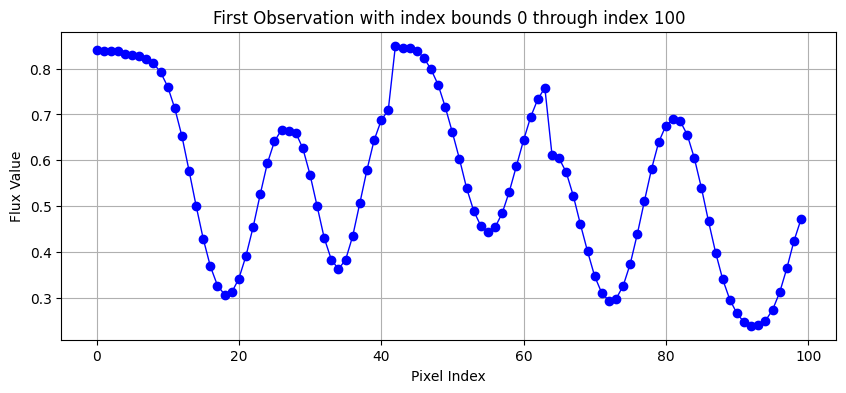

In [150]:
# Plot the first observation's spectral slice from index 0 to 100
index1, index2 = 0, 100
data_array = first_observation[index1 : index2] #colon here

plt.figure(figsize=(10, 4))
plt.plot(range(index1, index2), data_array, marker='o', color='blue', linestyle='-', linewidth=1)
plt.title("First Observation with index bounds " + str(index1) + " through index " + str(index2))
plt.xlabel("Pixel Index")
plt.ylabel("Flux Value")
plt.grid(True)
plt.show()

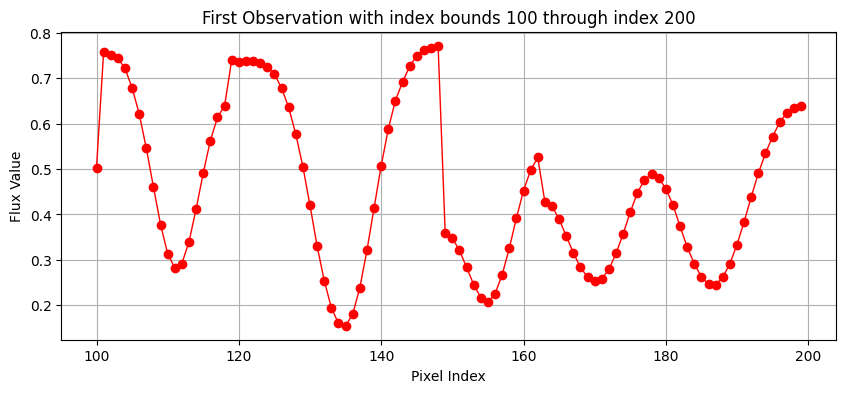

In [151]:
# Plot the first observation's spectral slice from index 0 to 100
index1, index2 = 100, 200
data_array = first_observation[index1 : index2] #colon here

plt.figure(figsize=(10, 4))
plt.plot(range(index1, index2), data_array, marker='o', color='red', linestyle='-', linewidth=1)
plt.title("First Observation with index bounds " + str(index1) + " through index " + str(index2))
plt.xlabel("Pixel Index")
plt.ylabel("Flux Value")
plt.grid(True)
plt.show()

# Notice how the previous code was quite repetitive? It's easier to use functions for these types of tasks like plotting. Here is an example function below:

In [152]:
def plot_spectral_slice(data_array, start_idx, end_idx, observation_name, stats=True, color='orange'):
    # I think it's okay to use AI for doc strings, which explains what a function does.
    '''
    Plots a slice of a 1D observation array, with options to compute and overlay
    key statistics (min, max, mean) on the visualization using calculate_range_stats.

    Parameters:
    data_array (numpy.ndarray): The 1D array representing a single spectrum/observation.
    start_idx (int): The starting index of the slice (inclusive).
    end_idx (int): The ending index of the slice (exclusive).
    stats (bool): If True, computes and displays the min, max, and mean statistics on the plot.
    '''
    # Slice the data based on the indices
    data_slice = data_array[start_idx:end_idx]
    indices = np.arange(start_idx, end_idx)

    # Create the plot
    plt.figure(figsize=(12, 5))
    plt.plot(indices, data_slice, marker='o', color=color, linestyle='-', linewidth=1, label='Spectrum')

    if stats:
        # Call our pre-existing calculate_range_stats function!!!
        # Pay attention to the function call here
        stats_array = calculate_range_stats(data_array, start_idx, end_idx)
        min_val, max_val, mean_val = stats_array[0], stats_array[1], stats_array[2]

        # Plot horizontal line for the mean
        plt.axhline(mean_val, color='green', linestyle='--', linewidth=1.5, label=f'Mean ({mean_val:.3f})')

        # Plot min and max markers, need to get the index here.
        min_idx = indices[np.argmin(data_slice)]
        max_idx = indices[np.argmax(data_slice)]
        plt.scatter(min_idx, min_val, color='blue', s=100, zorder=5, label=f'Min ({min_val:.3f})')
        plt.scatter(max_idx, max_val, color='red', s=100, zorder=5, label=f'Max ({max_val:.3f})')

    # Styling
    plt.title(f"{observation_name} Observation with index bounds {start_idx} through index {end_idx}")
    plt.xlabel("Pixel Index")
    plt.ylabel("Flux Value")
    plt.grid(True)
    plt.legend(loc='best')
    plt.show()

--- Statistics for Index Range [100:200] ---
Minimum Value : 0.155044
Maximum Value : 0.771139
Mean Value    : 0.457954



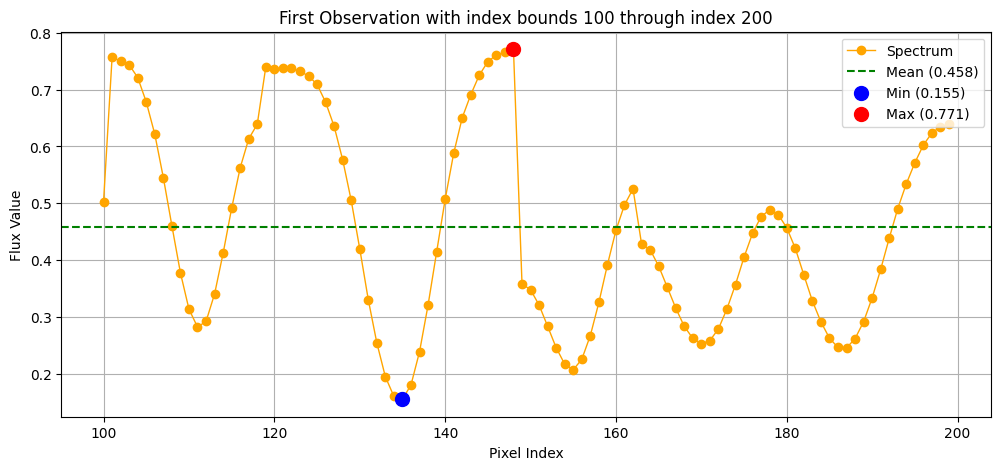

In [178]:
# --- Demo execution of the new function ---
plot_spectral_slice(first_observation, 100, 200, 'First', stats=True)

## Let's look at another observation date! We looked at the first observation, which happens in 2015, but let's look at an observation that happens about a year later, towards number 448 in the dataset of 2036 observations total.

--- Statistics for Index Range [100:200] ---
Minimum Value : 0.154150
Maximum Value : 0.773926
Mean Value    : 0.458185



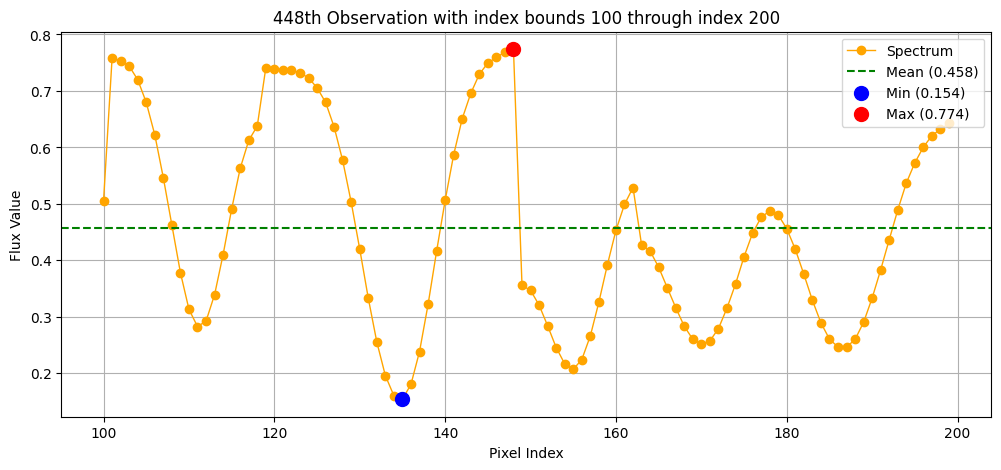

In [154]:
print(data.shape)
random_observation = data[448]
plot_spectral_slice(random_observation, 100, 200, '448th', stats=True)

# Great work so far! There are two complications to cover

## 1. We have been using pixels so far but, the data natively has wavelength grids.

## 2. Let's produce a timeseries of the data, as that can become very informative for understanding variability trends.

## First we do the wavelength data here:

In [155]:
# Load the wavelength array
wavelengths = np.loadtxt('waves_kitcat.txt')
print("Wavelength Array Shape:", wavelengths.shape)
print('\n')
print(wavelengths[0])
print('\n')
print(      wavelengths[0:10]       )

Wavelength Array Shape: (31066,)


3910.153564453125


[3910.15356445 3910.16357422 3910.17358398 3910.18359375 3910.19360352
 3910.20361328 3910.21362305 3910.22363281 3910.23339844 3910.2434082 ]


# Let's plot the data in wavelength space, but we still specify the data in pixel space just to stay familiar

--- Statistics for Index Range [100:200] ---
Minimum Value : 0.155044
Maximum Value : 0.771139
Mean Value    : 0.457954



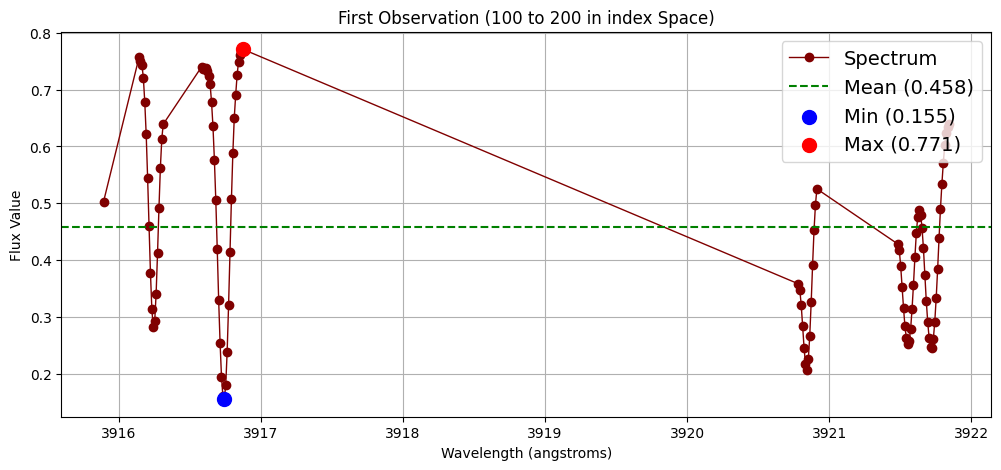

In [192]:
def plot_spectral_slice_wavelength(data_array, start_idx, end_idx, observation_name, stats=True, color='orange'):
    ''' Some type of documentation string here. '''
    # Slice both data and wavelengths using the pixel indices
    data_slice = data_array[start_idx:end_idx]
    wavelength_slice = wavelengths[start_idx:end_idx]

    # Plot in wavelength space
    plt.figure(figsize=(12, 5))
    plt.plot(wavelength_slice, data_slice, marker='o', color=color, linestyle='-', linewidth=1, label='Spectrum')
    #plt.scatter(wavelength_slice, data_slice, marker='o', color=color, ) #linestyle='-', linewidth=1, label='Spectrum')

    if stats:
        stats_array = calculate_range_stats(data_array, start_idx, end_idx)
        min_val, max_val, mean_val = stats_array[0], stats_array[1], stats_array[2]

        # Plot the mean line and min/max markers in wavelength coordinates
        plt.axhline(mean_val, color='green', linestyle='--', linewidth=1.5, label=f'Mean ({mean_val:.3f})')
        min_wl = wavelength_slice[np.argmin(data_slice)] ##--> argmin(dataslice) ; 125, and then we do wavelength_slice[125]
        max_wl = wavelength_slice[np.argmax(data_slice)]
        plt.scatter(min_wl, min_val, color='blue', s=100, zorder=5, label=f'Min ({min_val:.3f})')
        plt.scatter(max_wl, max_val, color='red', s=100, zorder=5, label=f'Max ({max_val:.3f})')

    plt.title(f"{observation_name} Observation ({start_idx} to {end_idx} in index Space)")
    plt.xlabel("Wavelength (angstroms)")
    plt.ylabel("Flux Value")
    plt.grid(True)
    plt.legend(loc='upper right', fontsize=14)
    plt.show()

# Quick test run
plot_spectral_slice_wavelength(first_observation, 100, 200, 'First', stats=True,  color='maroon')

# Now the last thing we want to do is a time series. Usually the bottom of an absorption line is interesting, it's the greatest depth and so corresponds to the greatst blockage of light, indicating perhaps that there is a high abundance of a molecule in the photosphere or the molecular abundance is very low in the atmosphere height of the star's photosphere. In either case, we may be interested in how the photosphere evolves over time. Let's load up the date array.

In [194]:
# Load the time dataset
time_df = pd.read_csv('time_df.csv')

# Assuming the time is stored under 'time' or similar; let's display the columns first to check
print("Columns in DataFrame:", list(time_df.columns))

#display(time_df.head(20))       # Pandas is something useful to use for analyzing tables of data rather than an array
display(time_df.tail(20))

Columns in DataFrame: ['Unnamed: 0', 'year', 'month', 'day', 'hour', 'minutes', 'seconds', 'msec', 'date', 'jdb']


,Unnamed: 0,year,month,day,hour,minutes,seconds,msec,date,jdb
2016,2016,2023,12,4,0,45,31,727,2023-12-04 00:45:31.727,60282.531617
2017,2017,2023,12,7,23,57,58,153,2023-12-07 23:57:58.153,60286.498590
2018,2018,2023,12,9,0,55,21,416,2023-12-09 00:55:21.416,60287.538442
2019,2019,2023,12,10,1,1,2,143,2023-12-10 01:01:02.143,60288.542386
2020,2020,2023,12,11,0,54,44,42,2023-12-11 00:54:44.042,60289.538010
2021,2021,2023,12,12,0,56,55,970,2023-12-12 00:56:55.970,60290.539537
2022,2022,2023,12,13,1,13,12,807,2023-12-13 01:13:12.807,60291.550843
2023,2023,2023,12,14,0,47,2,841,2023-12-14 00:47:02.841,60292.532672
2024,2024,2023,12,15,1,11,31,404,2023-12-15 01:11:31.404,60293.549669
2025,2025,2023,12,16,1,32,2,545,2023-12-16 01:32:02.545,60294.563918


# For convenience, we can subtract the earliest date, so that the units are relative to zero.

In [195]:
# Calculate the relative time in days using the explicit 'jdb' column
time_df['relative_days'] = time_df['jdb'] - time_df['jdb'].min()
display(time_df[['jdb', 'relative_days']].head())

,jdb,relative_days
0,57220.549961,0.000000
1,57223.490539,2.940577
2,57233.513604,12.963642
3,57234.557402,14.007440
4,57235.533549,14.983588


# We've already explored plotting the spectra for different observations. Now we can attach the observations to specific days. Let's create a time series for the data. For example, 2023 had a lot of stellar variability, so we might be interested in the last 365 days of our observation data, if you do time_df.tail() you'll see that the dataset extends to the beginning of 2024. Let's plot a metric as a function of time for 2024: perhaps we compute the minimum flux as a function of time for pixels within the wavelength range 5000 to 5100 angstroms. Let's implement this plot below, and then write it as a function. First the standalone plot:

## Here we filter the data by wavelength (standalone) and then we filter the data for observations greater than 2023

In [159]:
# 1. Find pixel index boundaries by locating where wavelengths are between 5000 and 5100
matching_indices = np.where((wavelengths >= 5000) & (wavelengths <= 5100))[0]
start_idx = matching_indices[0]
end_idx = matching_indices[-1] + 1
print(f"Wavelength 5000-5100 A corresponds to pixel indices: [{start_idx}:{end_idx}]")

# 2. Directly get times and observation indices for years 2023 and 2024

#update this later.
recent_obs = time_df[time_df['year'] >= 2023] #2023 and after had a lot of stellar variability.
filtered_times = recent_obs['relative_days'].values
filtered_indices = recent_obs.index.values

print('\n')
print('sample index selection below')
print(filtered_indices[0:10])
print('\n')
print(f"Number of observations in 2023-2024: {len(filtered_indices)}")

Wavelength 5000-5100 A corresponds to pixel indices: [11699:13662]


sample index selection below
[1796 1797 1798 1799 1800 1801 1802 1803 1804 1805]


Number of observations in 2023-2024: 240


## Next we iterate over the filtered_indices, which are the observation dates, and then we extract the smaller spectra from the 5000 to 5100 angstrom range, and then we compute the minimum flux value here, this probably corresponds to the minimum of a specific absorption line

In [160]:
# 3. Extract minimum flux for each of these observations using our stats function
min_fluxes = []

for idx in filtered_indices:
    observation_data = data[idx] #this is from our original data array from earlier!!
    observation_selection = observation_data[start_idx:end_idx]
    min_value = np.min(observation_selection)
    min_fluxes.append(min_value)

min_fluxes = np.array(min_fluxes)

## Now we plot this time series:

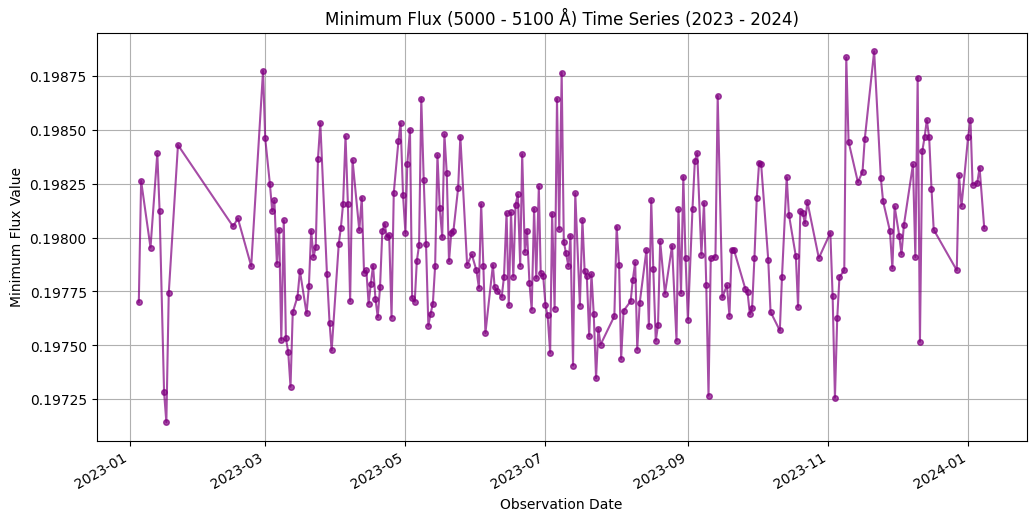

In [161]:
# 4. Plot the time series of minimum flux values using calendar dates
plt.figure(figsize=(12, 6))

# Convert the 'date' column string to actual datetime objects for beautiful date formatting on the x-axis
calendar_dates = pd.to_datetime(recent_obs['date'])

plt.plot(calendar_dates, min_fluxes, marker='o', linestyle='-', color='purple', markersize=4, alpha=0.7)
plt.title("Minimum Flux (5000 - 5100 Å) Time Series (2023 - 2024)")
plt.xlabel("Observation Date")
plt.ylabel("Minimum Flux Value")
plt.grid(True)
plt.gcf().autofmt_xdate() # Automatically rotates and formats the date labels nicely
plt.show()

# Task 1:

### Create a function that generalizes the procedure we just did. This function should take the starting and ending years of interest as arguments, then filter the observations to include only those years, including both endpoints. Then, for each observation, it should select the wavelength range of interest (so the starting and ending wavelengths should also be arguments of the function). Within that wavelength range, compute the minimum flux value for each observation. Then plot those minimum flux values as a time series, with the observation dates on the x-axis and the minimum flux values on the y-axis.

### Bonus challenge: The function should be written with minimum first. You can also try computing different statistics within the wavelength range of interest, such as the mean, maximum, standard deviation, or more advanced computational techniques. Add a method argument to your function, i.e., method = 'mean', meaning that for each observation, you will compute the mean flux across the selected wavelength pixels instead of the minimum. As a good practice, you can separate the calculation section of your data within the function, to isolate where you choose which method to use. The plotted time series will then show how that quantity changes over time. The function signature is given below:

In [162]:
def plot_minimum_time_series(start_year, end_year, wave_start, wave_end, method='min', color='red'):
    '''
    Plots a time series of a computed metric (min, max, mean, std) within a specified
    wavelength range across a filtered range of observation years.

    Parameters:
    start_year (int): The starting year (inclusive) for filtering observation dates.
    end_year (int): The ending year (inclusive) for filtering observation dates.
    wave_start (float): The starting wavelength boundary in Angstroms.
    wave_end (float): The ending wavelength boundary in Angstroms.
    method (str): The statistical method to apply: 'min', 'max', 'mean', or 'std'.
    color (str): Line color for the plot.
    '''
    ## Write your code here:



    return None

# If your function works, you should be able to reproduce a plot similar to the one above. Uncomment the code below and see if you can reproduce the plot from earlier

In [163]:
plot_minimum_time_series(start_year=2023, end_year=2024, wave_start=5000, wave_end=5100, method='min', color='purple')


#Task 2

## Goal: Identify which wavelength ranges show the largest changes in flux relative to the average spectrum over the observing period.

## First, write a function (or baby step) that computes the master spectrum by averaging the flux at each wavelength pixel across all observations. Treat this as our reference spectrum, and plot it over the full available wavelength range (approximately 3900–7000 angstroms). You can make the function below plot the master spectrum automatically each time it's called.

## For each observation, subtract the master spectrum from the observed spectrum, pixel by pixel: residual = observed spectrum - master spectrum. Each observation will now have its own residual spectrum.

## Next, divide a selected wavelength range into bins of width W angstroms. The wavelength limits and bin width should be function arguments. For example, the range 4000–6000 angstroms with W = 50 gives 40 bins. (2000/50 = 40).

## For each observation and each bin, compute the standard deviation of the residual flux values across the wavelength pixels inside that bin. This produces one value per bin per observation.

## Then, for each bin, average those standard deviations across all observations. The order matters: compute the standard deviation across wavelength pixels first, then average the resulting values over time.

## Write a function that performs this bin analysis and plots the results. Use the central wavelength of each bin on the x-axis and its time-averaged residual standard deviation on the y-axis. Identify the bin with the largest average value in standard deviation over time.

## Interpret this metric as the typical amount of wavelength-dependent variation within each bin relative to the master spectrum.

In [164]:
def analyze_spectral_variability_bins(wave_start, wave_end, bin_width):
    '''
    Performs a binned variability analysis on residual spectra to find which regions
    show the largest shape changes relative to the average master spectrum.

    Parameters:
    wave_start (float): The starting wavelength of the analysis region in Angstroms.
    wave_end (float): The ending wavelength of the analysis region in Angstroms.
    bin_width (float): The width W of each wavelength bin in Angstroms.

    Returns:
    dict: A dictionary containing bin centers, time-averaged residual standard deviations,
          and the properties of the bin showing maximum variability.
    '''
    # Break down the steps into parts!
    # Use comments to highlight and break down specific steps, and feel free to print/plot as many things as you need within the function to accomplish your task

    return None

In [ ]:
# Example call to perform the binned variability analysis
# This analyzes the range 4000 to 6000 Angstroms using bins of width 50 Angstroms (resulting in 40 bins)
analysis_results = analyze_spectral_variability_bins(wave_start=4000, wave_end=6000, bin_width=50) #angstroms here.